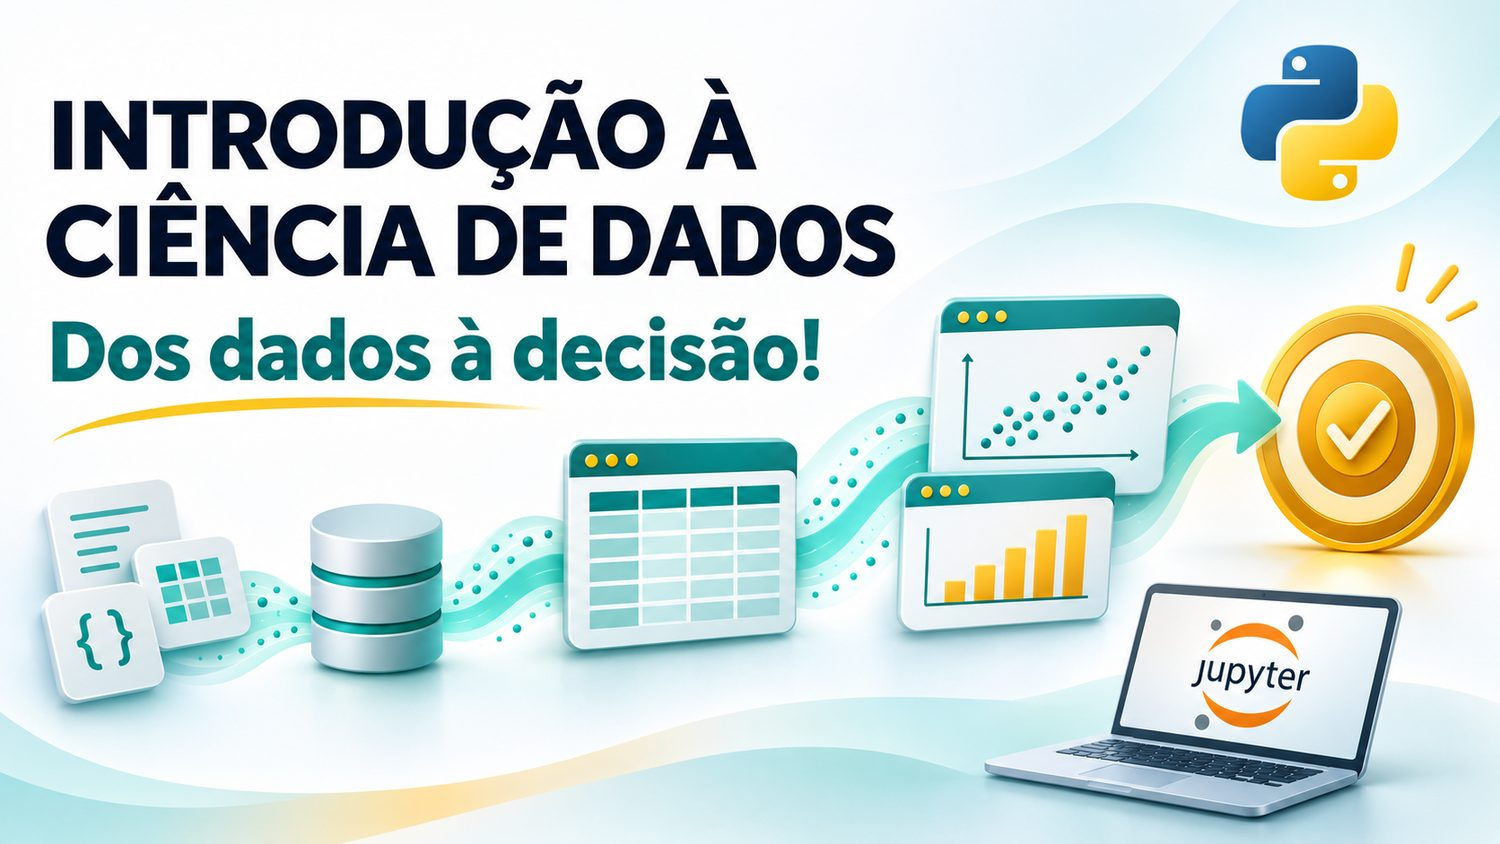

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_5_modelos_lineares/03_Regressao_Logistica.ipynb)

# Capítulo 3 – Regressão logística

A regressão linear prevê um número. Para prever uma **classe** (sim ou não) usa-se a sua parente mais próxima, a **regressão logística**. Apesar do nome, é um modelo de classificação: calcula a mesma soma ponderada dos atributos e transforma-a numa **probabilidade**. Já a usámos no módulo 1; aqui abrimo-la e construímo-la de raiz.

> **Objetivos:** perceber porque uma reta não serve para prever uma classe; conhecer a função sigmoide; relacionar probabilidade, possibilidades (*odds*) e o seu logaritmo; perceber a perda logarítmica; treinar o modelo de raiz por descida do gradiente; interpretar os coeficientes como razões de possibilidades; ver a fronteira de decisão; verificar se as probabilidades são fiáveis.

**Pré-requisitos:** capítulos 1 e 2, e o capítulo 3 do módulo 1 (matriz de confusão e limiar). A sintaxe está em [Scikit-Learn: classificação](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_2_avancado/N2_04_ScikitLearn_Classificacao.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

## O problema: o cliente vai aceitar o orçamento?

A empresa de painéis solares envia milhares de orçamentos por ano, e só uma parte é aceite. A equipa comercial quer saber **que orçamentos têm mais probabilidade de ser aceites**, para decidir a quem telefonar primeiro. Cada linha é um orçamento enviado. Os dados são sintéticos.

In [2]:
def gerar_orcamentos(n=4000, semente=83):
    """Gera orçamentos enviados por uma empresa fictícia de painéis solares (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    fatura = rng.gamma(4.0, 22, n).clip(25, 400).round()
    anos_retorno = (rng.normal(8.5, 2.2, n) - 0.008 * (fatura - 90)).clip(3, 16).round(1)
    visita = rng.random(n) < 0.4
    canal = rng.choice(["site", "recomendação", "feira"], n, p=[0.55, 0.25, 0.2])
    idade_casa = rng.integers(1, 60, n)
    z = (-0.9 - 0.42 * (anos_retorno - 8) + 0.004 * (fatura - 90) + 1.0 * visita
         + pd.Series(canal).map({"site": 0.0, "recomendação": 0.9, "feira": -0.3}).to_numpy())
    aceitou = rng.random(n) < 1 / (1 + np.exp(-z))
    return pd.DataFrame({"anos_retorno": anos_retorno, "fatura_mensal": fatura, "visita_presencial": visita, "canal": canal,
                         "idade_casa": idade_casa, "aceitou": aceitou})


orcamentos = gerar_orcamentos()
print(f"{len(orcamentos)} orçamentos, {orcamentos['aceitou'].mean():.1%} aceites")
orcamentos.head()

4000 orçamentos, 38.6% aceites


,anos_retorno,fatura_mensal,visita_presencial,canal,idade_casa,aceitou
0,9.9,33.0,False,site,48,False
1,10.2,79.0,False,feira,9,False
2,11.7,44.0,False,site,7,False
3,5.9,90.0,False,site,47,True
4,3.8,32.0,False,feira,1,True


| Coluna | Significado |
| --- | --- |
| `anos_retorno` | Anos que a instalação demora a pagar-se, segundo o orçamento |
| `fatura_mensal` | Fatura mensal de eletricidade do cliente, em euros |
| `visita_presencial` | Se um técnico visitou a casa antes do orçamento |
| `canal` | Como chegou o pedido: site, recomendação de outro cliente ou feira |
| `idade_casa` | Idade da casa, em anos |
| `aceitou` | Se o cliente aceitou o orçamento (o alvo) |

## Porque não uma reta?

O alvo vale 0 ou 1. Nada impede de lhe ajustar uma reta, com o tempo de retorno como atributo.

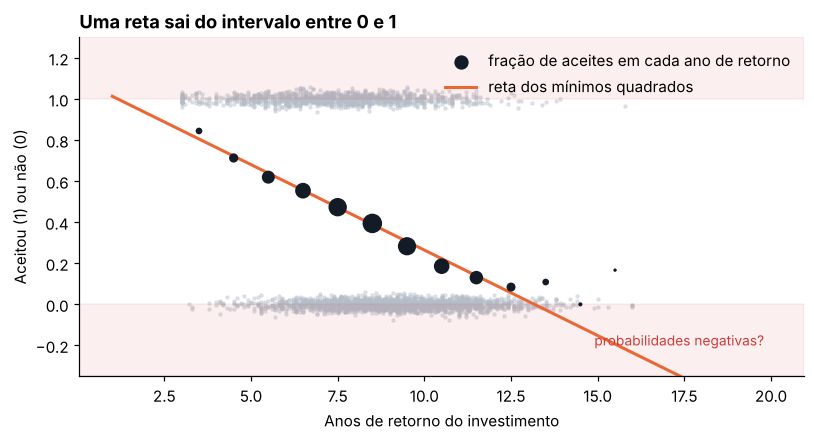

In [3]:
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split

treino, teste = train_test_split(orcamentos, test_size=0.25, random_state=0, stratify=orcamentos["aceitou"])
x, y = treino["anos_retorno"].to_numpy(), treino["aceitou"].to_numpy().astype(float)

reta = LinearRegression().fit(x.reshape(-1, 1), y)
eixo = np.linspace(1, 20, 200)
classes = pd.cut(treino["anos_retorno"], np.arange(3, 17, 1))
taxa = treino.groupby(classes, observed=True)["aceitou"].agg(["mean", "size"])
centros = np.array([c.mid for c in taxa.index])

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.scatter(x, y + np.random.default_rng(0).normal(0, 0.02, len(y)), s=4, color=CINZA, alpha=0.35)
ax.scatter(centros, taxa["mean"], s=taxa["size"] / 4, color=TINTA, zorder=3, label="fração de aceites em cada ano de retorno")
ax.plot(eixo, reta.predict(eixo.reshape(-1, 1)), color=LARANJA, lw=2, label="reta dos mínimos quadrados")
ax.axhspan(-0.35, 0, color=MAU, alpha=0.08)
ax.axhspan(1, 1.3, color=MAU, alpha=0.08)
ax.text(19.8, -0.2, "probabilidades negativas?", ha="right", color=MAU, fontsize=9)
ax.set_ylim(-0.35, 1.3)
ax.set_xlabel("Anos de retorno do investimento")
ax.set_ylabel("Aceitou (1) ou não (0)")
ax.set_title("Uma reta sai do intervalo entre 0 e 1")
ax.legend(frameon=False, loc="upper right")
plt.show()

Os pontos cinzentos são os orçamentos (em cima os aceites, em baixo os recusados). Os pontos pretos resumem-nos: a fração de aceites para cada tempo de retorno. Quanto mais depressa o investimento se paga, mais clientes aceitam.

A reta acompanha a tendência a meio e falha nas pontas:

- prevê valores **negativos** para retornos longos e, prolongando, **acima de 1** para retornos muito curtos. Não são probabilidades;
- assume que cada ano a mais tira sempre a mesma quantidade. Mas uma probabilidade perto de 0 já não tem por onde descer: a relação tem de **achatar** nos extremos.

Precisamos de uma função que transforme qualquer número num valor entre 0 e 1, em forma de S.

## A função sigmoide

> **sigmoide(z) = 1 ÷ (1 + e⁻ᶻ)**

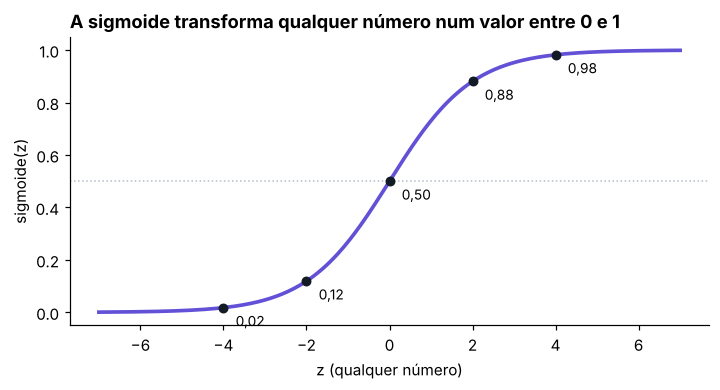

In [4]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))


z = np.linspace(-7, 7, 300)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(z, sigmoide(z), color=VIOLETA, lw=2.4)
for valor in [-4, -2, 0, 2, 4]:
    ax.scatter([valor], [sigmoide(valor)], color=TINTA, zorder=3, s=30)
    ax.annotate(f"{sigmoide(valor):.2f}".replace(".", ","), (valor, sigmoide(valor)), textcoords="offset points", xytext=(8, -12), fontsize=9)
ax.axhline(0.5, color=CINZA, lw=1, ls=":")
ax.set_xlabel("z (qualquer número)")
ax.set_ylabel("sigmoide(z)")
ax.set_title("A sigmoide transforma qualquer número num valor entre 0 e 1")
plt.show()

- z = 0 dá 0,5;
- valores positivos grandes aproximam-se de 1, negativos grandes de 0, sem nunca lá chegar;
- a meio, a curva é quase uma reta; nas pontas, achata.

## O modelo

A regressão logística junta as duas peças: a soma ponderada do capítulo 2 e a sigmoide.

> **z = b₀ + b₁ × atributo₁ + … + bₖ × atributoₖ**
>
> **probabilidade = sigmoide(z)**

Com um só atributo:

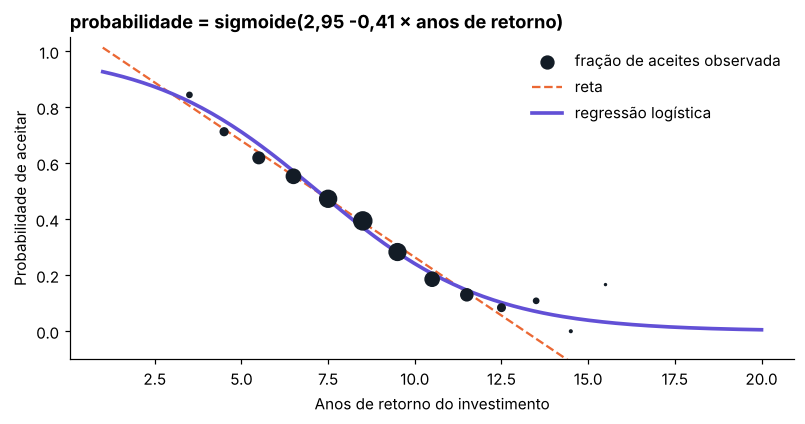

In [5]:
um = LogisticRegression(C=1e6).fit(x.reshape(-1, 1), y)             # C muito alto: sem regularização (capítulo 4)
b0, b1 = um.intercept_[0], um.coef_[0, 0]

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.scatter(centros, taxa["mean"], s=taxa["size"] / 4, color=TINTA, zorder=3, label="fração de aceites observada")
ax.plot(eixo, reta.predict(eixo.reshape(-1, 1)), color=LARANJA, lw=1.5, ls="--", label="reta")
ax.plot(eixo, sigmoide(b0 + b1 * eixo), color=VIOLETA, lw=2.4, label="regressão logística")
ax.set_ylim(-0.1, 1.05)
ax.set_xlabel("Anos de retorno do investimento")
ax.set_ylabel("Probabilidade de aceitar")
ax.set_title(f"probabilidade = sigmoide({b0:.2f} {b1:+.2f} × anos de retorno)".replace(".", ","))
ax.legend(frameon=False, loc="upper right")
plt.show()

A curva em S acompanha as frações observadas em toda a extensão e nunca sai do intervalo entre 0 e 1.

## Ler os coeficientes: possibilidades

Na regressão linear, o coeficiente era «kWh por kWp». Aqui, o coeficiente soma-se a **z**, e z não é uma probabilidade. Para lhe dar significado precisamos de um conceito intermédio.

As **possibilidades** (*odds*) são a razão entre a probabilidade de acontecer e a de não acontecer: p ÷ (1 − p). É a linguagem das apostas: «três para um».

| Probabilidade | Possibilidades | Lê-se | z = logaritmo das possibilidades |
| --- | --- | --- | --- |
| 0,10 | 0,11 | 1 para 9 | −2,2 |
| 0,25 | 0,33 | 1 para 3 | −1,1 |
| 0,50 | 1 | 1 para 1 | 0 |
| 0,75 | 3 | 3 para 1 | +1,1 |
| 0,90 | 9 | 9 para 1 | +2,2 |

A sigmoide e o logaritmo das possibilidades são funções inversas uma da outra. Por isso, **z é o logaritmo das possibilidades**, e o modelo é linear **nessa escala**:

> **log(possibilidades) = b₀ + b₁ × atributo₁ + …**

Daqui sai a leitura dos coeficientes:

- aumentar um atributo em uma unidade **soma** b ao logaritmo das possibilidades;
- o que é o mesmo que **multiplicar** as possibilidades por **eᵇ**. A este número chama-se **razão de possibilidades** (*odds ratio*).

In [6]:
print(f"Coeficiente dos anos de retorno: {b1:.3f}  →  razão de possibilidades: {np.exp(b1):.2f}")
print(f"Cada ano a mais de retorno multiplica as possibilidades de aceitar por {np.exp(b1):.2f} (reduz {1 - np.exp(b1):.0%}).\n")
for anos in [5, 6, 9, 10, 13, 14]:
    p = sigmoide(b0 + b1 * anos)
    print(f"  retorno em {anos:>2} anos: probabilidade {p:.2f} | possibilidades {p / (1 - p):.2f}")

Coeficiente dos anos de retorno: -0.410  →  razão de possibilidades: 0.66
Cada ano a mais de retorno multiplica as possibilidades de aceitar por 0.66 (reduz 34%).

  retorno em  5 anos: probabilidade 0.71 | possibilidades 2.47
  retorno em  6 anos: probabilidade 0.62 | possibilidades 1.64
  retorno em  9 anos: probabilidade 0.32 | possibilidades 0.48
  retorno em 10 anos: probabilidade 0.24 | possibilidades 0.32
  retorno em 13 anos: probabilidade 0.09 | possibilidades 0.09
  retorno em 14 anos: probabilidade 0.06 | possibilidades 0.06


As **possibilidades** multiplicam-se sempre pelo mesmo fator de um ano para o seguinte. A **probabilidade** não muda sempre o mesmo: a meio da curva, um ano faz muita diferença; nas pontas, quase nenhuma. É por isso que o efeito de um atributo numa regressão logística se descreve em possibilidades, e não em pontos de probabilidade.

## Como se escolhem os coeficientes: a perda logarítmica

Na regressão linear minimizámos o quadrado dos resíduos. Aqui usa-se outra medida, a **perda logarítmica** (*log-loss*), que avalia a probabilidade que o modelo deu **ao que realmente aconteceu**:

> **perda = −log(probabilidade atribuída ao resultado verdadeiro)**

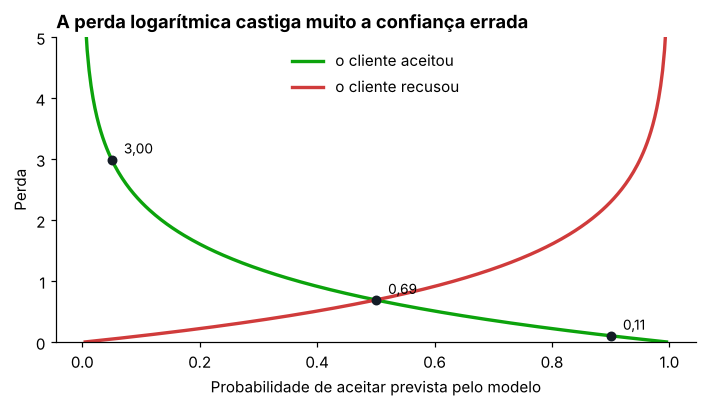

In [7]:
p = np.linspace(0.005, 0.995, 300)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(p, -np.log(p), color=BOM, lw=2.2, label="o cliente aceitou")
ax.plot(p, -np.log(1 - p), color=MAU, lw=2.2, label="o cliente recusou")
for prob in [0.9, 0.5, 0.05]:
    ax.scatter([prob], [-np.log(prob)], color=TINTA, zorder=3, s=30)
    ax.annotate(f"{-np.log(prob):.2f}".replace(".", ","), (prob, -np.log(prob)), textcoords="offset points", xytext=(8, 4), fontsize=9)
ax.set_ylim(0, 5)
ax.set_xlabel("Probabilidade de aceitar prevista pelo modelo")
ax.set_ylabel("Perda")
ax.set_title("A perda logarítmica castiga muito a confiança errada")
ax.legend(frameon=False, loc="upper center")
plt.show()

Se o cliente aceitou e o modelo tinha dito 0,9, a perda é pequena. Se tinha dito 0,5, é moderada. Se tinha dito 0,05, a perda é enorme: o modelo estava **confiante e errado**. Dizer 0 a algo que acontece dá uma perda infinita.

A perda do modelo é a média das perdas de todos os orçamentos. Minimizá-la obriga o modelo a dar probabilidades altas ao que acontece e a não ser mais confiante do que os dados justificam. (Em estatística chama-se a isto o método da **máxima verosimilhança**.)

## Treinar de raiz

Ao contrário da regressão linear, aqui **não existe fórmula** para os melhores coeficientes. Usa-se a descida do gradiente do capítulo 2. O gradiente da perda logarítmica tem uma forma muito parecida com o da regressão linear:

> **gradiente = (1 / n) × Xᵀ (probabilidades previstas − y)**

Só mudou o cálculo das previsões, que passam pela sigmoide.

In [8]:
def perda_logaritmica(y, p):
    p = np.clip(p, 1e-12, 1 - 1e-12)                       # evita log(0)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


def regressao_logistica(X, y, taxa=0.5, passos=3000):
    """Treina por descida do gradiente. X já inclui a coluna de uns."""
    b = np.zeros(X.shape[1])
    historico = []
    for _ in range(passos):
        p = sigmoide(X @ b)
        historico.append(perda_logaritmica(y, p))
        b = b - taxa * X.T @ (p - y) / len(y)
    return b, historico


numericas = ["anos_retorno", "fatura_mensal", "idade_casa"]


def preparar(dados, media=None, desvio=None):
    """Normaliza as colunas numéricas e codifica as restantes (referência do canal: site)."""
    tabela = dados[numericas].astype(float)
    media = tabela.mean() if media is None else media
    desvio = tabela.std() if desvio is None else desvio
    tabela = (tabela - media) / desvio
    tabela["visita_presencial"] = dados["visita_presencial"].astype(float)
    for canal in ["recomendação", "feira"]:
        tabela[f"canal_{canal}"] = (dados["canal"] == canal).astype(float)
    return tabela, media, desvio


X_treino, media, desvio = preparar(treino)
X_teste, _, _ = preparar(teste, media, desvio)
y_teste = teste["aceitou"].to_numpy().astype(float)

b, historico = regressao_logistica(np.column_stack([np.ones(len(X_treino)), X_treino]), y)
oficial = LogisticRegression(C=1e6, max_iter=1000).fit(X_treino, y)
pd.DataFrame({"de raiz": b, "scikit-learn": np.append(oficial.intercept_, oficial.coef_[0])}, index=["ordenada na origem"] + list(X_treino.columns)).round(3)

,de raiz,scikit-learn
ordenada na origem,-1.086,-1.086
anos_retorno,-0.943,-0.943
fatura_mensal,0.180,0.180
idade_casa,-0.037,-0.037
visita_presencial,0.893,0.893
canal_recomendação,0.843,0.844
canal_feira,-0.382,-0.383


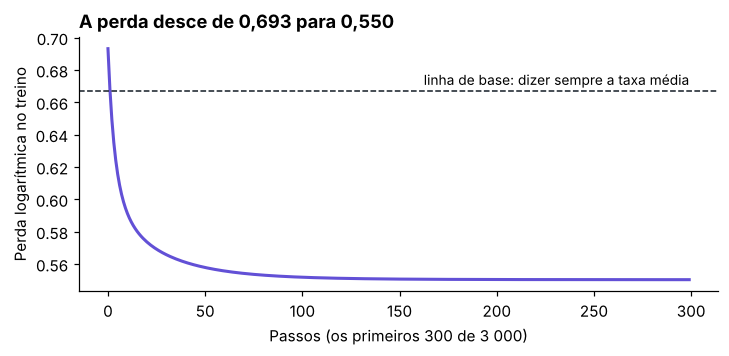

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3))
ax.plot(historico[:300], color=VIOLETA, lw=2)
ax.axhline(perda_logaritmica(y, np.full(len(y), y.mean())), color=TINTA, ls="--", lw=1)
ax.text(299, perda_logaritmica(y, np.full(len(y), y.mean())) + 0.004, "linha de base: dizer sempre a taxa média", ha="right", fontsize=9)
ax.set_xlabel("Passos (os primeiros 300 de 3 000)")
ax.set_ylabel("Perda logarítmica no treino")
ax.set_title(f"A perda desce de {historico[0]:.3f} para {historico[-1]:.3f}".replace(".", ","))
plt.show()

A nossa implementação chega aos mesmos coeficientes que o scikit-learn. A perda parte de 0,693 (o valor de quem diz 0,5 a tudo: −log 0,5) e desce abaixo da linha de base.

Uma nota sobre o scikit-learn: a sua `LogisticRegression` aplica **regularização** por omissão, que encolhe os coeficientes. Para os comparar com os nossos, desligámo-la com um valor muito alto de `C`. O capítulo 4 explica o que é e porque existe.

## Interpretar o modelo completo

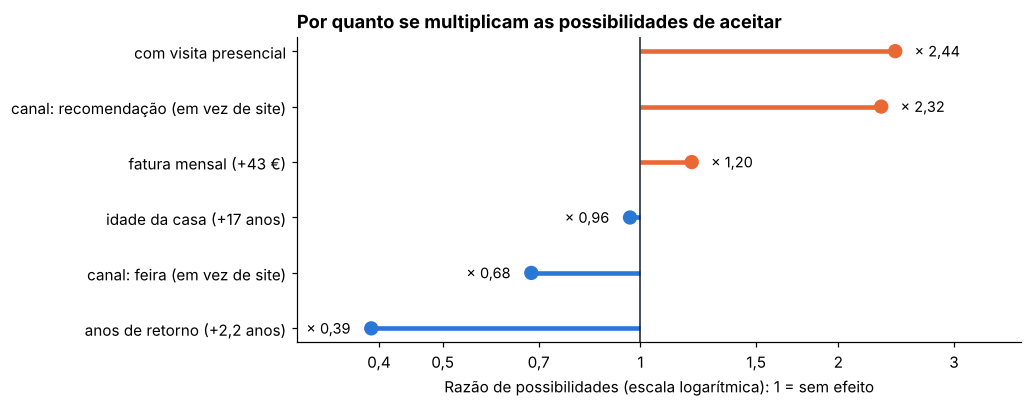

In [10]:
razoes = np.exp(pd.Series(oficial.coef_[0], index=X_treino.columns)).sort_values()
nomes = {"anos_retorno": f"anos de retorno (+{desvio['anos_retorno']:.1f} anos)", "fatura_mensal": f"fatura mensal (+{desvio['fatura_mensal']:.0f} €)",
         "idade_casa": f"idade da casa (+{desvio['idade_casa']:.0f} anos)", "visita_presencial": "com visita presencial",
         "canal_recomendação": "canal: recomendação (em vez de site)", "canal_feira": "canal: feira (em vez de site)"}

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.hlines(range(len(razoes)), 1, razoes, color=[LARANJA if v > 1 else AZUL for v in razoes], lw=3)
ax.scatter(razoes, range(len(razoes)), color=[LARANJA if v > 1 else AZUL for v in razoes], s=70, zorder=3)
for i, v in enumerate(razoes):
    ax.text(v * (1.07 if v > 1 else 0.93), i, f"× {v:.2f}".replace(".", ","), va="center", ha="left" if v > 1 else "right", fontsize=9.5)
ax.axvline(1, color=TINTA, lw=1)
ax.set_xscale("log")
ax.set_xticks([0.4, 0.5, 0.7, 1, 1.5, 2, 3], ["0,4", "0,5", "0,7", "1", "1,5", "2", "3"])
ax.minorticks_off()
ax.set_xlim(0.3, 3.8)
ax.set_yticks(range(len(razoes)), [nomes[n].replace(".", ",") for n in razoes.index])
ax.set_xlabel("Razão de possibilidades (escala logarítmica): 1 = sem efeito")
ax.set_title("Por quanto se multiplicam as possibilidades de aceitar")
plt.show()

Cada linha lê-se «mantendo o resto constante», como no capítulo 2.

- Uma **visita presencial** multiplica por cerca de 2,4 as possibilidades de o orçamento ser aceite, e uma **recomendação** por 2,3.
- Cada desvio-padrão a mais no **tempo de retorno** (cerca de dois anos) reduz as possibilidades para menos de metade.
- A **idade da casa** tem uma razão praticamente igual a 1: não tem efeito.

Uma razão de possibilidades de 2 **não quer dizer** «o dobro da probabilidade». Se a probabilidade era 0,10 (possibilidades de 0,11), passa para cerca de 0,18; se era 0,50, passa para 0,67.

E continua a ser uma associação. Os clientes que receberam visita podem ser os que já estavam mais interessados; para saber o efeito de visitar, seria preciso uma experiência (módulo 1, capítulo 5).

## A fronteira de decisão é uma reta

Para classificar, compara-se a probabilidade com um limiar. Com 0,5, o modelo diz «aceita» quando z > 0. Como z é uma soma ponderada, a fronteira entre as duas respostas é uma **linha reta** (um plano, com mais atributos).

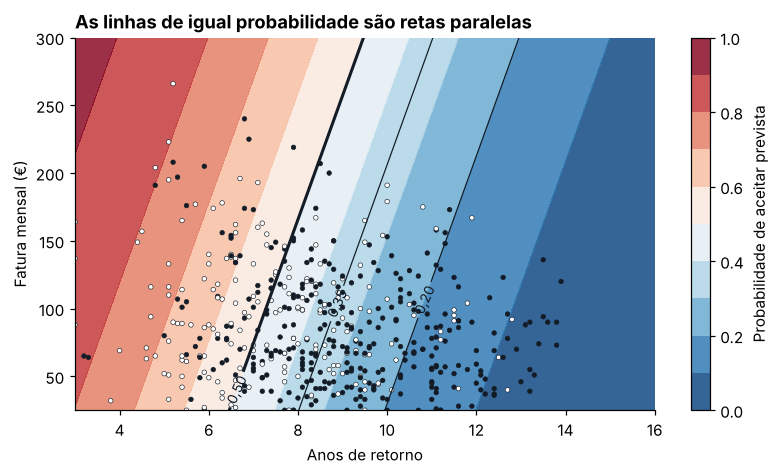

In [11]:
dois = ["anos_retorno", "fatura_mensal"]
plano = LogisticRegression(C=1e6, max_iter=5000).fit(treino[dois], y)
gx, gy = np.meshgrid(np.linspace(3, 16, 200), np.linspace(25, 300, 200))
prob = plano.predict_proba(pd.DataFrame({"anos_retorno": gx.ravel(), "fatura_mensal": gy.ravel()}))[:, 1].reshape(gx.shape)

fig, ax = plt.subplots(figsize=(8.5, 4.4))
mapa = ax.contourf(gx, gy, prob, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.85)
linhas = ax.contour(gx, gy, prob, levels=[0.2, 0.35, 0.5], colors=TINTA, linewidths=[0.8, 0.8, 2])
ax.clabel(linhas, fmt=lambda v: f"{v:.2f}".replace(".", ","), fontsize=9)
visiveis = treino.sample(500, random_state=1)
ax.scatter(visiveis["anos_retorno"], visiveis["fatura_mensal"], s=9, color=np.where(visiveis["aceitou"], "white", TINTA), edgecolor=TINTA, linewidth=0.4)
fig.colorbar(mapa, ax=ax, label="Probabilidade de aceitar prevista")
ax.set_xlabel("Anos de retorno")
ax.set_ylabel("Fatura mensal (€)")
ax.grid(False)
ax.set_title("As linhas de igual probabilidade são retas paralelas")
plt.show()

As cores são a probabilidade prevista; os pontos brancos são orçamentos aceites e os pretos, recusados. A linha grossa é a fronteira com o limiar 0,5.

Mudar o limiar **desloca** a fronteira, sempre paralela a si própria. Não a pode curvar. É o limite deste modelo: se a separação verdadeira entre as classes for curva ou tiver várias zonas, uma regressão logística só a aproxima, a menos que lhe demos atributos transformados (como fizemos com o quadrado da inclinação no capítulo 2). O módulo 6 apresenta modelos sem esta restrição.

## As probabilidades são de confiança?

Um modelo de classificação pode acertar muitas classes e dar probabilidades erradas. Diz-se que está **calibrado** quando, entre os casos a que atribui 30%, cerca de 30% acontecem.

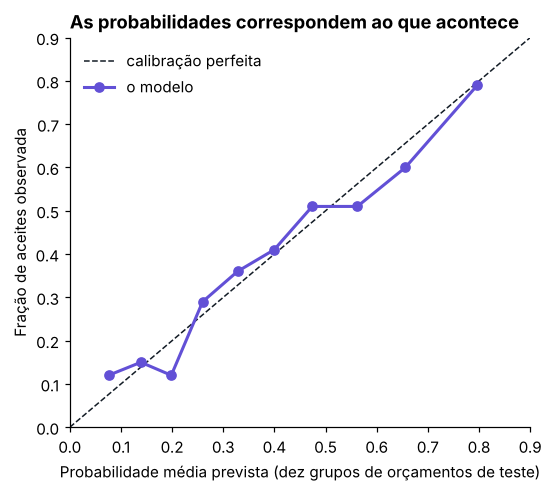

In [12]:
prob_teste = oficial.predict_proba(X_teste)[:, 1]
grupos = pd.qcut(prob_teste, 10, duplicates="drop")
calibracao = pd.DataFrame({"prevista": prob_teste, "observada": y_teste}).groupby(grupos, observed=True).mean()

fig, ax = plt.subplots(figsize=(5.4, 4.6))
ax.plot([0, 1], [0, 1], color=TINTA, ls="--", lw=1, label="calibração perfeita")
ax.plot(calibracao["prevista"], calibracao["observada"], "o-", color=VIOLETA, lw=2, label="o modelo")
ax.legend(frameon=False, loc="upper left")
ax.set_xlim(0, 0.9)
ax.set_ylim(0, 0.9)
ax.set_xlabel("Probabilidade média prevista (dez grupos de orçamentos de teste)")
ax.set_ylabel("Fração de aceites observada")
ax.set_title("As probabilidades correspondem ao que acontece")
plt.show()

Cada ponto junta um décimo dos orçamentos de teste. Os pontos seguem a diagonal: quando o modelo diz 20%, cerca de 20% aceitam; quando diz 60%, cerca de 60%.

A regressão logística costuma ser bem calibrada, porque a perda logarítmica premeia precisamente isso. É uma vantagem importante sempre que a probabilidade é usada para **decidir** (por exemplo, para calcular o valor esperado de um telefonema), e não apenas para ordenar.

### Do modelo à decisão

In [13]:
linha_de_base = max(y_teste.mean(), 1 - y_teste.mean())
previsto = prob_teste >= 0.5
print(f"Exatidão no teste: {(previsto == y_teste).mean():.1%}   (dizer sempre «recusa»: {linha_de_base:.1%})")
print(f"Perda logarítmica no teste: {perda_logaritmica(y_teste, prob_teste):.3f}   (dizer sempre a taxa média: {perda_logaritmica(y_teste, np.full(len(y_teste), y.mean())):.3f})")

ordem = np.argsort(-prob_teste)
quinto = len(ordem) // 5
print(f"\nSe a equipa só puder telefonar a um quinto dos clientes ({quinto} orçamentos):")
print(f"  escolhidos ao acaso:       {y_teste.mean():.0%} aceitam")
print(f"  os que o modelo põe à frente: {y_teste[ordem[:quinto]].mean():.0%} aceitam")

Exatidão no teste: 69.6%   (dizer sempre «recusa»: 61.4%)
Perda logarítmica no teste: 0.568   (dizer sempre a taxa média: 0.667)

Se a equipa só puder telefonar a um quinto dos clientes (200 orçamentos):
  escolhidos ao acaso:       39% aceitam
  os que o modelo põe à frente: 70% aceitam


A exatidão melhora só alguns pontos em relação a «dizer sempre que recusa». Aceitar um orçamento depende de muita coisa que não está nos dados, e nenhum modelo adivinha cliente a cliente.

Mas a pergunta da equipa comercial era outra: **a quem telefonar primeiro**. Aí o modelo é útil: entre os orçamentos que põe à frente, a taxa de aceitação é quase o dobro da média. É a lição do módulo 1: um modelo avalia-se pela decisão que apoia.

## Pontos fortes e limitações

| Pontos fortes | Limitações |
| --- | --- |
| Dá probabilidades, em geral bem calibradas | Fronteira de decisão linear |
| Os coeficientes leem-se (razões de possibilidades) | Interações e curvas têm de ser dadas como atributos |
| Rápida de treinar, mesmo com muitos dados | Sensível a atributos muito correlacionados |
| Boa linha de base para qualquer problema de classificação | Com classes perfeitamente separáveis, os coeficientes crescem sem limite (capítulo 4) |

## Exercícios

### `Exercício 1` – Contas com possibilidades

Um orçamento tem uma probabilidade de aceitação de 0,20. (a) Quais são as possibilidades? (b) Uma visita presencial multiplica as possibilidades por 2,4. Qual é a nova probabilidade? (c) Repete a alínea (b) para um orçamento que partia de 0,60. Em qual dos dois casos a probabilidade subiu mais?

<details>
<summary><b>Ver uma solução possível</b></summary>

- (a) 0,20 ÷ 0,80 = **0,25** (1 para 4).
- (b) Novas possibilidades: 0,25 × 2,4 = 0,6. Probabilidade = 0,6 ÷ 1,6 = **0,375**. Subiu 17,5 pontos.
- (c) Possibilidades iniciais: 0,60 ÷ 0,40 = 1,5; novas: 3,6; probabilidade = 3,6 ÷ 4,6 ≈ **0,78**. Subiu cerca de 18 pontos.

Neste exemplo os dois ganhos são parecidos, por coincidência dos valores. A partir de 0,05 a subida seria de apenas 6 pontos (para 0,11), e a partir de 0,95 seria de 3 (para 0,98): a mesma razão de possibilidades dá ganhos de probabilidade muito diferentes conforme o ponto de partida.

</details>

### `Exercício 2` – A perda de dois modelos

Dois modelos preveem cinco orçamentos, dos quais os três primeiros foram aceites. O modelo A dá as probabilidades 0,9; 0,8; 0,6; 0,3; 0,2. O modelo B dá 0,99; 0,99; 0,02; 0,01; 0,01. Calcula a exatidão (limiar 0,5) e a perda logarítmica de cada um, com a função `perda_logaritmica`. Qual é melhor?

In [14]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
real = np.array([1, 1, 1, 0, 0.0])
for nome, p in [("A", np.array([0.9, 0.8, 0.6, 0.3, 0.2])), ("B", np.array([0.99, 0.99, 0.02, 0.01, 0.01]))]:
    print(f"Modelo {nome}: exatidão {np.mean((p >= 0.5) == real):.0%} | perda logarítmica {perda_logaritmica(real, p):.3f}")
```

O modelo A acerta os cinco, com uma perda baixa. O modelo B acerta quatro com enorme confiança e erra um, também com enorme confiança (deu 2% a um orçamento que foi aceite). Esse único erro custa-lhe uma perda várias vezes maior do que a de A. A perda logarítmica prefere um modelo prudente a um modelo confiante que às vezes se engana redondamente.

</details>

### `Exercício 3` – O efeito da normalização nos coeficientes

Treina a regressão logística com as colunas numéricas **sem normalizar** (usa o scikit-learn, com `C=1e6` e `max_iter=5000`). O coeficiente dos anos de retorno muda? E as probabilidades previstas no teste? Como se relacionam os dois coeficientes?

In [15]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
def sem_normalizar(dados):
    tabela, _, _ = preparar(dados, media=0, desvio=1)
    return tabela


cru = LogisticRegression(C=1e6, max_iter=5000).fit(sem_normalizar(treino), y)
print(f"Coeficiente dos anos de retorno: {cru.coef_[0][0]:.3f} (sem normalizar) | {oficial.coef_[0][0]:.3f} (normalizado)")
print(f"Coeficiente normalizado ÷ desvio-padrão: {oficial.coef_[0][0] / desvio['anos_retorno']:.3f}")
print(f"Maior diferença entre as probabilidades no teste: {np.abs(cru.predict_proba(sem_normalizar(teste))[:, 1] - prob_teste).max():.4f}")
```

O coeficiente muda de valor porque muda de unidade: sem normalizar é «por ano»; normalizado é «por desvio-padrão». Um obtém-se do outro dividindo pelo desvio-padrão. As probabilidades previstas são as mesmas. Num modelo sem regularização, a escala dos atributos muda a leitura dos coeficientes e não muda as previsões. (Com regularização já não é assim, como veremos no capítulo 4.)

</details>

### `Exercício 4` – Uma interação

O efeito da visita presencial será o mesmo em todos os canais? Acrescenta ao modelo a coluna `visita_presencial × canal_feira` e vê o coeficiente. Compara a perda logarítmica no teste com e sem ela. O que concluis?

In [16]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
def com_interacao(X):
    return X.assign(visita_na_feira=X["visita_presencial"] * X["canal_feira"])


m = LogisticRegression(C=1e6, max_iter=1000).fit(com_interacao(X_treino), y)
print(f"Coeficiente da interação: {m.coef_[0][-1]:+.3f}")
print(f"Perda no teste: sem interação {perda_logaritmica(y_teste, prob_teste):.4f} | com interação {perda_logaritmica(y_teste, m.predict_proba(com_interacao(X_teste))[:, 1]):.4f}")
```

O coeficiente da interação é pequeno e a perda no teste não melhora (pode até piorar ligeiramente). Nestes dados, a visita tem o mesmo efeito em todos os canais, e a coluna nova só acrescenta um coeficiente a estimar. Nem toda a interação imaginável existe; a forma de saber é testá-la em dados que o modelo não viu.

</details>

## Verifica o que aprendeste

- [ ] Sei porque uma reta não serve para prever uma probabilidade.
- [ ] Sei o que faz a função sigmoide.
- [ ] Sei converter entre probabilidade, possibilidades e logaritmo das possibilidades.
- [ ] Sei o que mede a perda logarítmica.
- [ ] Sei treinar uma regressão logística por descida do gradiente.
- [ ] Sei interpretar um coeficiente como razão de possibilidades.
- [ ] Sei porque a fronteira de decisão é linear.
- [ ] Sei verificar se as probabilidades estão calibradas.

## Leitura recomendada

- https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
- https://scikit-learn.org/stable/modules/calibration.html
- https://en.wikipedia.org/wiki/Logistic_regression
- https://en.wikipedia.org/wiki/Odds_ratio